# People Analytics: Employee Attrition & Retention

## Análisis de factores asociados a la rotación de empleados

**Especialidad:** Data Analytics  
**Herramientas:** Python, Pandas, NumPy, Matplotlib, Seaborn  
**Dataset:** IBM HR Analytics Employee Attrition & Performance

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Exploración inicial de los datos

In [2]:
df = pd.read_csv("../data/WA_Fn-UseC_-HR-Employee-Attrition.csv")

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
df.shape

(1470, 35)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

### 1.1 Calidad y consistencia de los datos

In [5]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df["EmployeeNumber"].duplicated().sum()

np.int64(0)

In [8]:
df[["EmployeeCount", "Over18", "StandardHours"]].nunique()

EmployeeCount    1
Over18           1
StandardHours    1
dtype: int64

In [9]:
df["Attrition"].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [10]:
df["Attrition"].value_counts(normalize=True) * 100

Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64

Lo que acabamos de descubrir
Revisión	Resultado
Registros	1,470
Variables	35
Duplicados	0
EmployeeNumber duplicados	0
Valores nulos	0
EmployeeCount valores únicos	1
Over18 valores únicos	1
StandardHours valores únicos	1
Attrition = No	1,233 (83.88%)
Attrition = Yes	237 (16.12%)

Esto nos dice algo importante: Attrition está bastante desbalanceada. Aproximadamente 84% permanecieron y 16% abandonaron.

In [11]:
df_analysis = df.copy()

columns_to_drop = ["EmployeeCount", "Over18", "StandardHours"]

df_analysis = df_analysis.drop(columns=columns_to_drop)

df_analysis.shape

(1470, 32)

In [12]:
categorical_columns = df_analysis.select_dtypes(include="object").columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df_analysis[column].unique())


Attrition:
['Yes' 'No']

BusinessTravel:
['Travel_Rarely' 'Travel_Frequently' 'Non-Travel']

Department:
['Sales' 'Research & Development' 'Human Resources']

EducationField:
['Life Sciences' 'Other' 'Medical' 'Marketing' 'Technical Degree'
 'Human Resources']

Gender:
['Female' 'Male']

JobRole:
['Sales Executive' 'Research Scientist' 'Laboratory Technician'
 'Manufacturing Director' 'Healthcare Representative' 'Manager'
 'Sales Representative' 'Research Director' 'Human Resources']

MaritalStatus:
['Single' 'Married' 'Divorced']

OverTime:
['Yes' 'No']


In [157]:
df_analysis.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0
JobSatisfaction,1470.0,2.728571,1.102846,1.0,2.00,3.0,4.00,4.0


## 2. Análisis exploratorio de la rotación

In [14]:
attrition_summary = (
    df_analysis["Attrition"]
    .value_counts()
    .rename_axis("Attrition")
    .reset_index(name="Employees")
)

attrition_summary["Percentage"] = (
    attrition_summary["Employees"] / len(df_analysis) * 100
)

attrition_summary

,Attrition,Employees,Percentage
0,No,1233,83.877551
1,Yes,237,16.122449


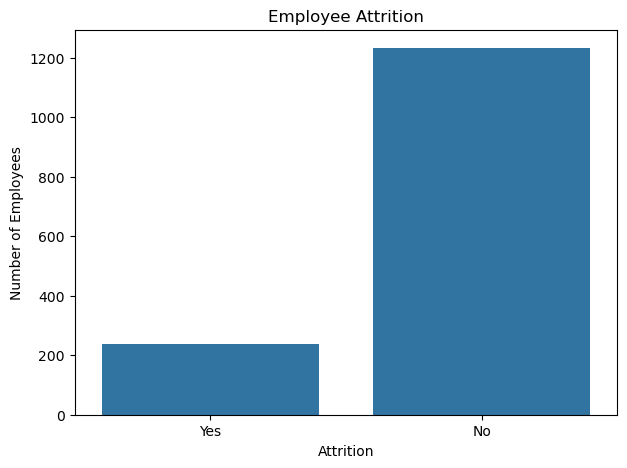

In [15]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_analysis,
    x="Attrition"
)

plt.title("Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.show()

In [16]:
def attrition_rate_by(column):
    result = (
        df_analysis.groupby(column)["Attrition"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="AttritionRate")
        .sort_values("AttritionRate", ascending=False)
    )
    
    return result

### Horas extra y rotación

In [17]:
attrition_rate_by("OverTime")

,OverTime,AttritionRate
1,Yes,30.528846
0,No,10.436433


### Hallazgo inicial: horas extra y rotación

La tasa de rotación observada es mayor entre los empleados que trabajan horas extra (30,53 %) que entre aquellos que no trabajan horas extra (10,44 %).

Esto representa una asociación observada en el conjunto de datos y no demuestra que las horas extra sean la causa de la rotación de empleados.


### Departamento y rotación

In [18]:
attrition_rate_by("Department")

,Department,AttritionRate
2,Sales,20.627803
0,Human Resources,19.047619
1,Research & Development,13.839750


### Frecuencia de viajes y rotación

In [19]:
attrition_rate_by("BusinessTravel")

,BusinessTravel,AttritionRate
1,Travel_Frequently,24.909747
2,Travel_Rarely,14.956855
0,Non-Travel,8.000000


### Rol del empleado y rotación

In [20]:
attrition_rate_by("JobRole")

,JobRole,AttritionRate
8,Sales Representative,39.759036
2,Laboratory Technician,23.938224
1,Human Resources,23.076923
7,Sales Executive,17.484663
6,Research Scientist,16.095890
4,Manufacturing Director,6.896552
0,Healthcare Representative,6.870229
3,Manager,4.901961
5,Research Director,2.500000


1. Lo que muestran los resultados

Department

Sales: 20,63 %
Human Resources: 19,05 %
Research & Development: 13,84 %

Hay diferencias entre departamentos, aunque no son tan grandes como las que vimos con overtime.

BusinessTravel

Travel_Frequently: 24,91 %
Travel_Rarely: 14,96 %
Non-Travel: 8,00 %

Aquí sí aparece un patrón bastante claro: la rotación observada aumenta entre quienes viajan con mayor frecuencia.

JobRole
Aquí hay diferencias mucho más marcadas. Por ejemplo:

Sales Representative: 39,76 %
Laboratory Technician: 23,94 %
Human Resources: 23,08 %
Manager: 4,90 %
Research Director: 2,50 %

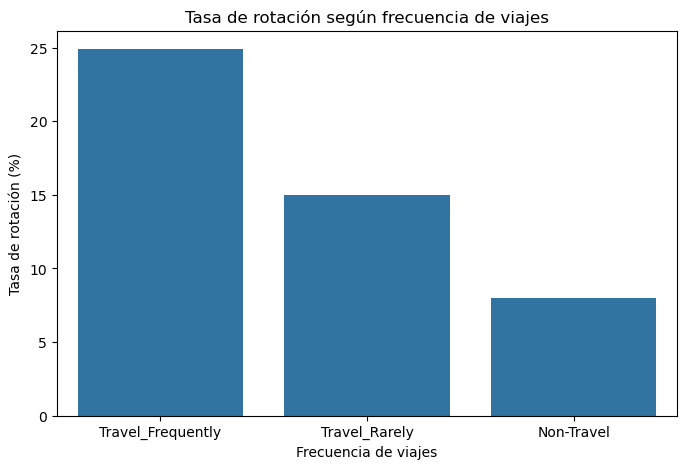

In [21]:
travel_attrition = attrition_rate_by("BusinessTravel")

plt.figure(figsize=(8, 5))

sns.barplot(
    data=travel_attrition,
    x="BusinessTravel",
    y="AttritionRate"
)

plt.title("Tasa de rotación según frecuencia de viajes")
plt.xlabel("Frecuencia de viajes")
plt.ylabel("Tasa de rotación (%)")

plt.show()

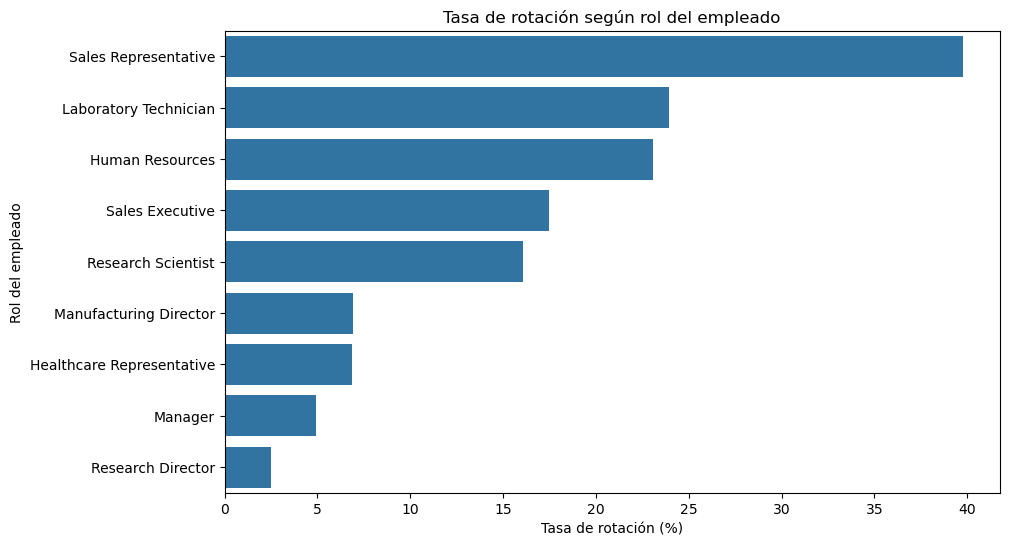

In [22]:
role_attrition = attrition_rate_by("JobRole")

plt.figure(figsize=(10, 6))

sns.barplot(
    data=role_attrition,
    x="AttritionRate",
    y="JobRole"
)

plt.title("Tasa de rotación según rol del empleado")
plt.xlabel("Tasa de rotación (%)")
plt.ylabel("Rol del empleado")

plt.show()

### Hallazgo inicial: rol del empleado y rotación

La tasa de rotación observada varía considerablemente según el rol del empleado. En particular, los **Sales Representatives** presentan la tasa más alta (39,76 %), seguidos por **Laboratory Technicians** (23,94 %) y empleados de **Human Resources** (23,08 %).

Por otro lado, los roles de **Research Director** (2,50 %), **Manager** (4,90 %) y **Healthcare Representative** (6,87 %) presentan tasas de rotación observadas considerablemente menores.

Estas diferencias representan asociaciones observadas en el conjunto de datos y no permiten concluir que el rol del empleado sea, por sí solo, la causa de la rotación.

Factor	Patrón observado
OverTime	30,53 % vs. 10,44 %
BusinessTravel	24,91 % en viajes frecuentes vs. 8,00 % sin viajes
JobRole	Desde 39,76 % hasta 2,50 % según el rol

In [23]:
df_analysis.groupby("Attrition")["Age"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,37.561233,8.88836,18.0,31.0,36.0,43.0,60.0
Yes,237.0,33.607595,9.68935,18.0,28.0,32.0,39.0,58.0


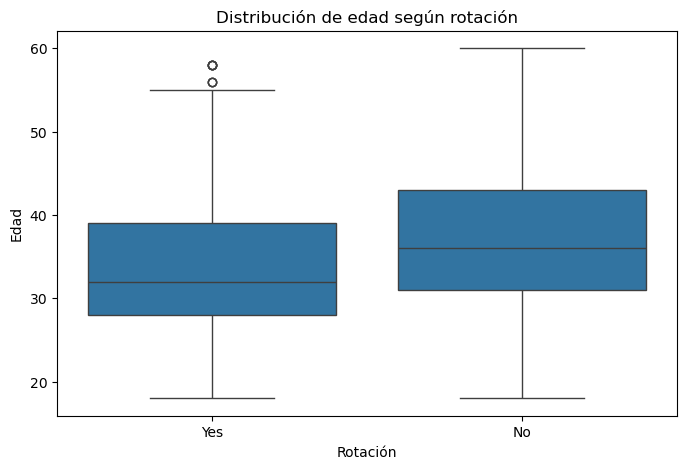

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="Age"
)

plt.title("Distribución de edad según rotación")
plt.xlabel("Rotación")
plt.ylabel("Edad")

plt.show()

En promedio:

Empleados que no salieron: 37,56 años
Empleados que sí salieron: 33,61 años

Es decir, en este dataset la edad promedio es aproximadamente 3,95 años menor entre quienes tuvieron Attrition = Yes.

In [25]:
df_analysis.groupby("Attrition")["MonthlyIncome"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,6832.739659,4818.208001,1051.0,3211.0,5204.0,8834.0,19999.0
Yes,237.0,4787.092827,3640.210367,1009.0,2373.0,3202.0,5916.0,19859.0


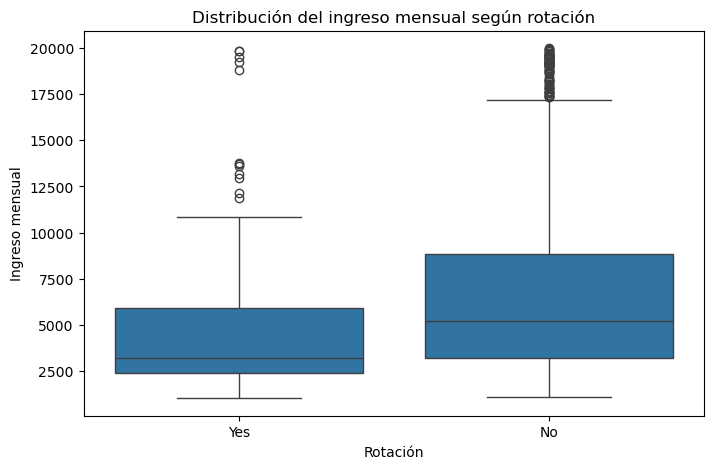

In [26]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="MonthlyIncome"
)

plt.title("Distribución del ingreso mensual según rotación")
plt.xlabel("Rotación")
plt.ylabel("Ingreso mensual")

plt.show()

El ingreso mensual promedio es:

No rotación: $6.832,74
Sí rotación: $4.787,09

La diferencia promedio es de aproximadamente $2.046 al mes.

Además, la mediana también es bastante diferente:

No: $5.204
Sí: $3.202

Esto sugiere que, en este dataset, los empleados con menores ingresos mensuales presentan una mayor presencia entre quienes abandonaron la empresa.

In [27]:
df_analysis.groupby("Attrition")["YearsAtCompany"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,7.369019,6.096298,0.0,3.0,6.0,10.0,37.0
Yes,237.0,5.130802,5.949984,0.0,1.0,3.0,7.0,40.0


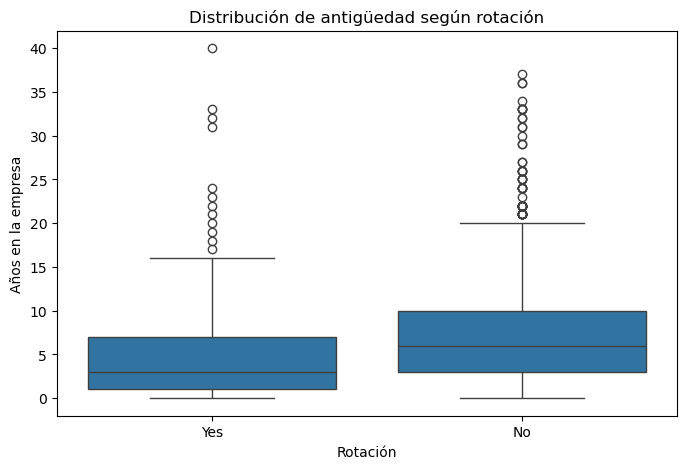

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="YearsAtCompany"
)

plt.title("Distribución de antigüedad según rotación")
plt.xlabel("Rotación")
plt.ylabel("Años en la empresa")

plt.show()

### Hallazgo inicial: antigüedad y rotación

La antigüedad en la empresa presenta diferencias entre los empleados que permanecieron y aquellos que salieron. La antigüedad promedio fue de 7,37 años entre quienes no presentaron rotación y de 5,13 años entre quienes sí la presentaron.

La diferencia también se observa en la mediana: 6 años para los empleados que permanecieron frente a 3 años para quienes salieron.

Estos resultados muestran una asociación entre la antigüedad y la rotación en este conjunto de datos, pero no permiten establecer que una menor antigüedad sea la causa de la rotación.


In [29]:
df_analysis.groupby("Attrition")["JobSatisfaction"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,2.778589,1.093277,1.0,2.0,3.0,4.0,4.0
Yes,237.0,2.468354,1.118058,1.0,1.0,3.0,3.0,4.0


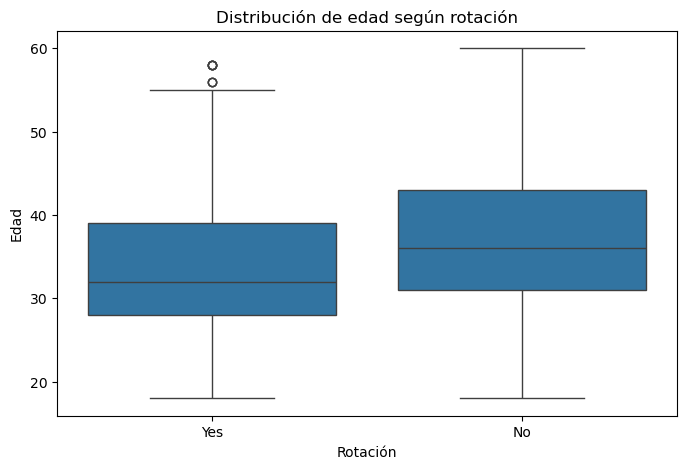

In [30]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="Age"
)

plt.title("Distribución de edad según rotación")
plt.xlabel("Rotación")
plt.ylabel("Edad")

plt.show()

La edad promedio es:

No rotación: 37,56 años
Sí rotación: 33,61 años

La diferencia es de aproximadamente 3,95 años.

Además, la mediana es:

No: 36 años
Sí: 32 años

Así que podemos decir que, en este dataset, los empleados que presentaron rotación tienden a ser más jóvenes en promedio.

In [31]:
df_analysis.groupby("Attrition")["EnvironmentSatisfaction"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,2.771290,1.071132,1.0,2.0,3.0,4.0,4.0
Yes,237.0,2.464135,1.169791,1.0,1.0,3.0,4.0,4.0


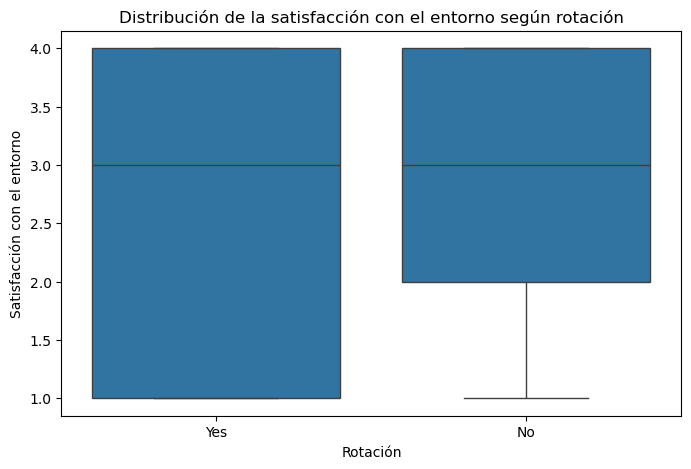

In [32]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="EnvironmentSatisfaction"
)

plt.title("Distribución de la satisfacción con el entorno según rotación")
plt.xlabel("Rotación")
plt.ylabel("Satisfacción con el entorno")

plt.show()

La satisfacción con el entorno de trabajo promedio fue:

No rotaron: 2,77
Sí rotaron: 2,46

Es decir, hay una diferencia de aproximadamente 0,31 puntos. Además, los cuartiles son algo más bajos en el grupo que presentó rotación:

No rotaron → Q1 = 2, mediana = 3, Q3 = 4
Sí rotaron → Q1 = 1, mediana = 3, Q3 = 4

La mediana es igual, así que la diferencia no es enorme, pero sí observamos una asociación entre el nivel de satisfacción con el entorno y la rotación.

In [33]:
df_analysis.groupby("Attrition")["WorkLifeBalance"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,2.781022,0.681907,1.0,2.0,3.0,3.0,4.0
Yes,237.0,2.658228,0.816453,1.0,2.0,3.0,3.0,4.0


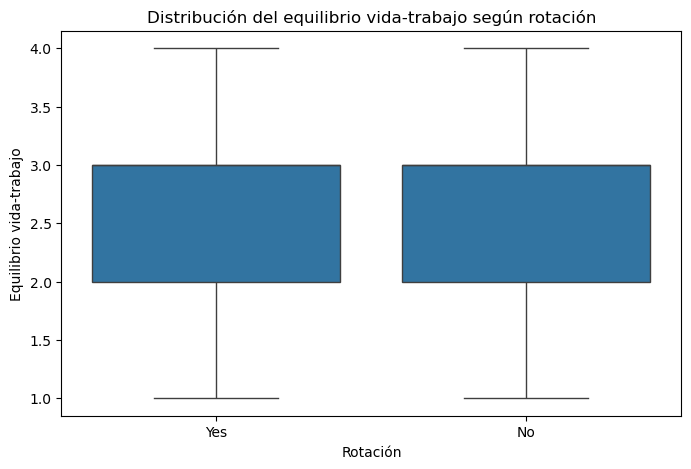

In [34]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="WorkLifeBalance"
)

plt.title("Distribución del equilibrio vida-trabajo según rotación")
plt.xlabel("Rotación")
plt.ylabel("Equilibrio vida-trabajo")

plt.show()

WorkLifeBalance y rotación
No rotaron: promedio 2,78
Sí rotaron: promedio 2,66
Diferencia: aproximadamente 0,12 puntos.
La mediana es 3 en ambos grupos.
Los cuartiles también son iguales: Q1 = 2 y Q3 = 3.

Así que, en este dataset, WorkLifeBalance muestra una asociación mucho más débil con la rotación que, por ejemplo, horas extra, rol, ingreso o antigüedad.

In [35]:
attrition_rate_by("JobLevel")

,JobLevel,AttritionRate
0,1,26.335175
2,3,14.678899
1,2,9.737828
4,5,7.246377
3,4,4.716981


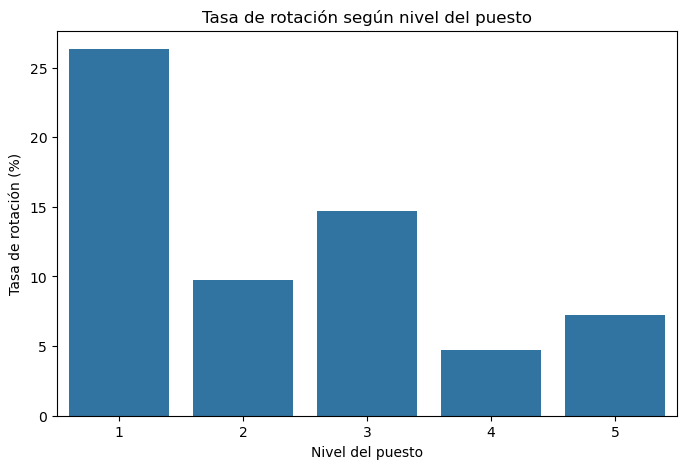

In [36]:
joblevel_attrition = attrition_rate_by("JobLevel")

plt.figure(figsize=(8, 5))

sns.barplot(
    data=joblevel_attrition,
    x="JobLevel",
    y="AttritionRate"
)

plt.title("Tasa de rotación según nivel del puesto")
plt.xlabel("Nivel del puesto")
plt.ylabel("Tasa de rotación (%)")

plt.show()

La tasa observada de rotación por nivel es:

JobLevel	Tasa de rotación
1	26,34 %
2	9,74 %
3	4,72 %
4	7,25 %
5	1,92 %

Aquí se ve un patrón bastante claro: los empleados de niveles más bajos presentan, en general, mayores tasas de rotación, especialmente el nivel 1.

### Hallazgo inicial: nivel del puesto y rotación

La tasa de rotación observada varía según el nivel del puesto. Los empleados de **JobLevel 1** presentan la tasa más alta de rotación (26,34 %), mientras que los niveles 2 y 3 presentan tasas de 9,74 % y 4,72 %, respectivamente.

Los niveles superiores muestran tasas de rotación observadas más bajas en este conjunto de datos, aunque el **JobLevel 5** debe interpretarse con cautela debido a su menor número de empleados.

En conjunto, los resultados muestran una **asociación entre el nivel del puesto y la rotación**, pero no permiten establecer que el nivel jerárquico sea, por sí solo, la causa de la salida de los empleados.


In [37]:
df_analysis.groupby("Attrition")["YearsInCurrentRole"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,4.484185,3.649402,0.0,2.0,3.0,7.0,18.0
Yes,237.0,2.902954,3.174827,0.0,0.0,2.0,4.0,15.0


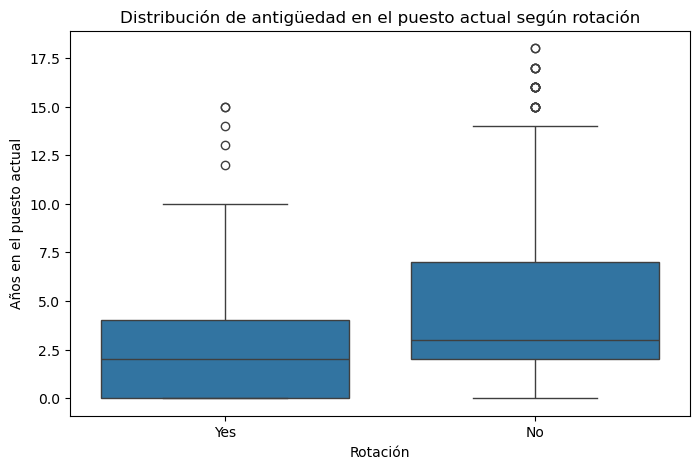

In [38]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="YearsInCurrentRole"
)

plt.title("Distribución de antigüedad en el puesto actual según rotación")
plt.xlabel("Rotación")
plt.ylabel("Años en el puesto actual")

plt.show()

earsInCurrentRole y rotación
No rotaron: promedio de 4,48 años
Sí rotaron: promedio de 2,90 años
Diferencia: aproximadamente 1,58 años.
Mediana:
No rotaron → 3 años
Sí rotaron → 2 años
El 25 % de quienes rotaron tiene 0 años en su rol actual, frente a 2 años entre quienes no rotaron.

Esto sugiere una asociación entre menor tiempo en el puesto actual y mayor rotación observada en este dataset.

### Hallazgo inicial: antigüedad en el puesto actual y rotación

La antigüedad en el puesto actual presenta diferencias entre los empleados que permanecieron y aquellos que presentaron rotación. El promedio fue de **4,48 años** entre quienes permanecieron y de **2,90 años** entre quienes salieron.

La mediana también fue menor en el grupo con rotación: **2 años**, frente a **3 años** entre quienes permanecieron. Además, el primer cuartil fue de **0 años** para quienes salieron y de **2 años** para quienes permanecieron.

Estos resultados muestran una **asociación entre una menor antigüedad en el puesto actual y una mayor rotación observada** en este conjunto de datos, pero no permiten establecer una relación causal.


In [39]:
df_analysis.groupby("Attrition")["YearsSinceLastPromotion"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,2.234388,3.234762,0.0,0.0,1.0,3.0,15.0
Yes,237.0,1.945148,3.153077,0.0,0.0,1.0,2.0,15.0


In [40]:
df_analysis.groupby("Attrition")["TrainingTimesLastYear"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,2.832928,1.293585,0.0,2.0,3.0,3.0,6.0
Yes,237.0,2.624473,1.254784,0.0,2.0,2.0,3.0,6.0


In [41]:
df_analysis.groupby("Attrition")["NumCompaniesWorked"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,2.645580,2.460090,0.0,1.0,2.0,4.0,9.0
Yes,237.0,2.940928,2.678519,0.0,1.0,1.0,5.0,9.0


In [42]:
df_analysis.groupby("Attrition")["DistanceFromHome"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,8.915653,8.012633,1.0,2.0,7.0,13.0,29.0
Yes,237.0,10.632911,8.452525,1.0,3.0,9.0,17.0,29.0


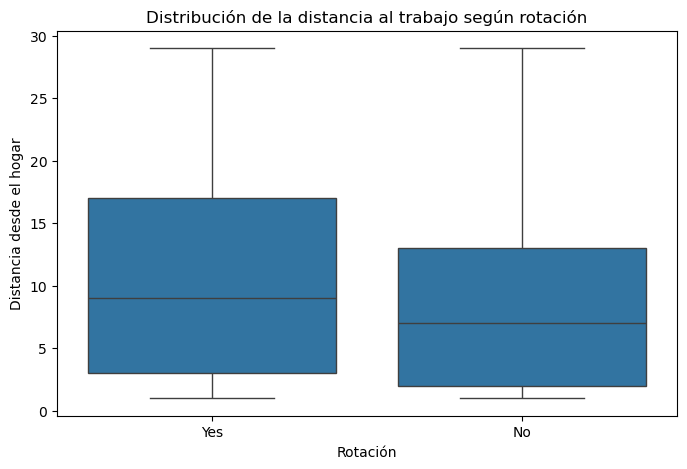

In [43]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="DistanceFromHome"
)

plt.title("Distribución de la distancia al trabajo según rotación")
plt.xlabel("Rotación")
plt.ylabel("Distancia desde el hogar")

plt.show()

DistanceFromHome y rotación
No rotaron: promedio de 8,92
Sí rotaron: promedio de 10,63
Diferencia: aproximadamente 1,72 unidades de distancia.
Mediana:
No → 7
Yes → 9
Q3:
No → 13
Yes → 17

Es decir, en este conjunto de datos, quienes presentaron rotación tendían a vivir más lejos del lugar de trabajo.

### Hallazgo inicial: distancia al trabajo y rotación

La distancia entre el hogar y el lugar de trabajo presenta diferencias entre los empleados que permanecieron y aquellos que presentaron rotación. La distancia promedio fue de **8,92** entre quienes permanecieron y de **10,63** entre quienes salieron.

La mediana también fue mayor en el grupo con rotación: **9**, frente a **7** entre quienes permanecieron. Además, el tercer cuartil fue de **17** para quienes salieron y de **13** para quienes permanecieron.

Estos resultados muestran una **asociación entre una mayor distancia al trabajo y una mayor rotación observada** en este conjunto de datos. Sin embargo, no permiten establecer que la distancia sea la causa de la rotación.


In [44]:
pd.crosstab(
    df_analysis["JobLevel"],
    df_analysis["OverTime"],
    values=df_analysis["Attrition"],
    aggfunc=lambda x: (x == "Yes").mean() * 100
)

OverTime,No,Yes
JobLevel,,
1,15.762274,52.564103
2,6.701031,17.808219
3,12.258065,20.634921
4,2.739726,9.090909
5,3.921569,16.666667


In [45]:
overtime_joblevel = (
    pd.crosstab(
        df_analysis["JobLevel"],
        df_analysis["OverTime"],
        values=df_analysis["Attrition"],
        aggfunc=lambda x: (x == "Yes").mean() * 100
    )
    .reset_index()
)

overtime_joblevel

OverTime,JobLevel,No,Yes
0,1,15.762274,52.564103
1,2,6.701031,17.808219
2,3,12.258065,20.634921
3,4,2.739726,9.090909
4,5,3.921569,16.666667


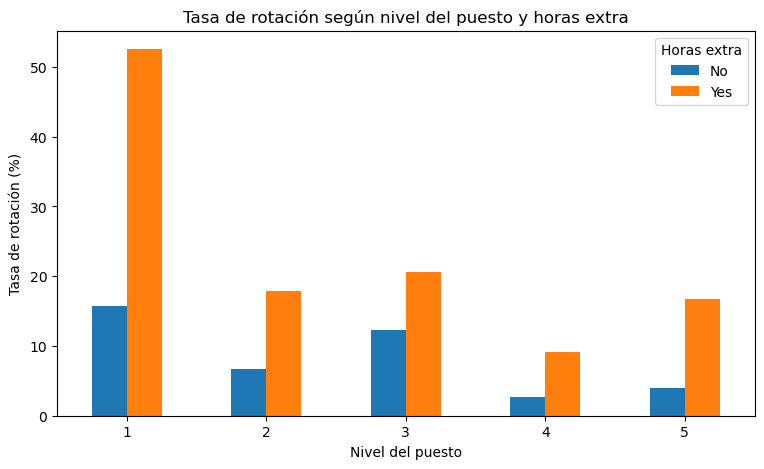

In [46]:
overtime_joblevel.plot(
    x="JobLevel",
    kind="bar",
    figsize=(9, 5)
)

plt.title("Tasa de rotación según nivel del puesto y horas extra")
plt.xlabel("Nivel del puesto")
plt.ylabel("Tasa de rotación (%)")
plt.xticks(rotation=0)
plt.legend(title="Horas extra")

plt.show()

### Hallazgo: horas extra, nivel del puesto y rotación

Al combinar el nivel del puesto con la condición de horas extra, se observan diferencias en la tasa de rotación.

La diferencia es especialmente marcada en **JobLevel 1**: la tasa de rotación observada fue de **15,76 %** entre quienes no trabajaban horas extra y de **52,56 %** entre quienes sí las trabajaban.

En los demás niveles también se observa una tasa de rotación mayor entre quienes trabajaban horas extra, aunque la magnitud de la diferencia varía según el nivel del puesto.

Este análisis muestra que la relación entre las horas extra y la rotación puede variar según el nivel del puesto. Se trata de asociaciones observadas en este conjunto de datos y no permiten establecer una relación causal.


In [47]:
pd.crosstab(
    df_analysis["JobSatisfaction"],
    df_analysis["OverTime"],
    values=df_analysis["Attrition"],
    aggfunc=lambda x: (x == "Yes").mean() * 100
)

OverTime,No,Yes
JobSatisfaction,,
1,17.560976,35.714286
2,9.478673,37.681159
3,9.968847,33.884298
4,6.940063,21.126761


In [48]:
overtime_satisfaction = (
    pd.crosstab(
        df_analysis["JobSatisfaction"],
        df_analysis["OverTime"],
        values=df_analysis["Attrition"],
        aggfunc=lambda x: (x == "Yes").mean() * 100
    )
    .reset_index()
)

overtime_satisfaction

OverTime,JobSatisfaction,No,Yes
0,1,17.560976,35.714286
1,2,9.478673,37.681159
2,3,9.968847,33.884298
3,4,6.940063,21.126761


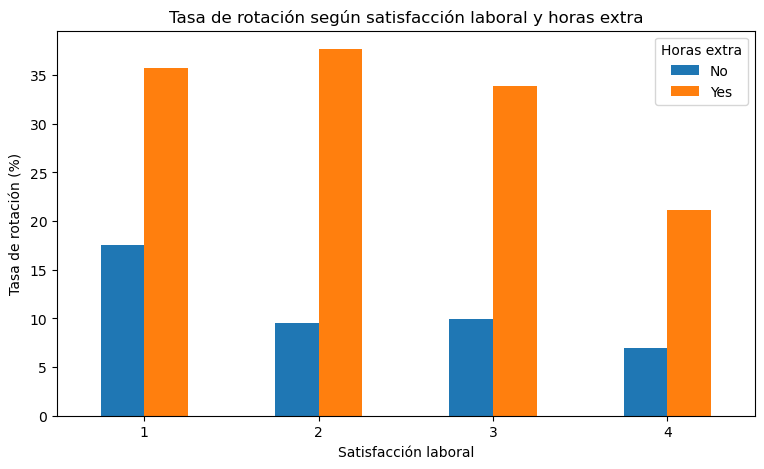

In [49]:
overtime_satisfaction.plot(
    x="JobSatisfaction",
    kind="bar",
    figsize=(9, 5)
)

plt.title("Tasa de rotación según satisfacción laboral y horas extra")
plt.xlabel("Satisfacción laboral")
plt.ylabel("Tasa de rotación (%)")
plt.xticks(rotation=0)
plt.legend(title="Horas extra")

plt.show()

### Hallazgo: satisfacción laboral, horas extra y rotación

Al analizar conjuntamente la satisfacción laboral y las horas extra, la tasa de rotación observada fue mayor entre los empleados que trabajaban horas extra en **todos los niveles de satisfacción laboral**.

La diferencia fue especialmente visible en los niveles de satisfacción **2 y 3**, donde la tasa de rotación fue de **37,68 %** y **33,88 %**, respectivamente, entre quienes trabajaban horas extra, frente a **9,48 %** y **9,97 %** entre quienes no trabajaban horas extra.

Incluso entre los empleados con el nivel más alto de satisfacción laboral (4), la tasa de rotación observada fue mayor cuando existían horas extra: **21,13 % frente a 6,94 %**.

Este resultado sugiere que la relación entre las horas extra y la rotación se mantiene dentro de los distintos niveles de satisfacción laboral en este conjunto de datos. Sin embargo, se trata de una asociación observada y no permite establecer una relación causal.


In [50]:
attrition_rate_by("StockOptionLevel")

,StockOptionLevel,AttritionRate
0,0,24.405705
3,3,17.647059
1,1,9.395973
2,2,7.594937


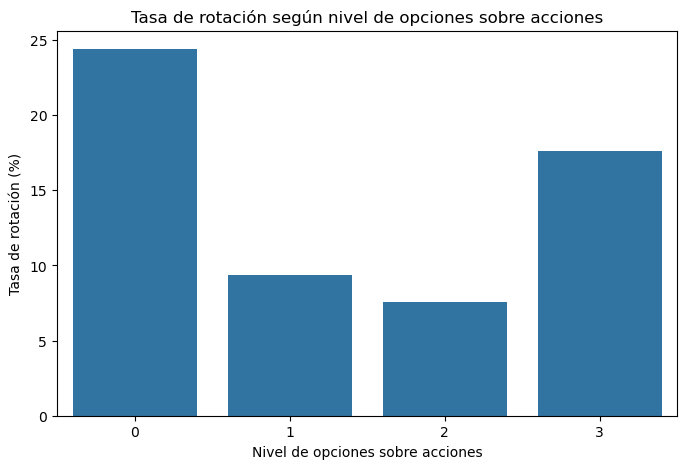

In [51]:
stock_attrition = attrition_rate_by("StockOptionLevel")

plt.figure(figsize=(8, 5))

sns.barplot(
    data=stock_attrition,
    x="StockOptionLevel",
    y="AttritionRate"
)

plt.title("Tasa de rotación según nivel de opciones sobre acciones")
plt.xlabel("Nivel de opciones sobre acciones")
plt.ylabel("Tasa de rotación (%)")

plt.show()

### Hallazgo: opciones sobre acciones y rotación

La tasa de rotación observada varía según el nivel de opciones sobre acciones. Los empleados con **StockOptionLevel = 0** presentan una tasa de rotación de **24,41 %**, mientras que los niveles 1 y 2 presentan tasas menores de **9,40 %** y **7,59 %**, respectivamente.

El nivel 3 presenta una tasa de rotación de **17,65 %**, por lo que no se observa una relación lineal simple entre el nivel de opciones sobre acciones y la rotación.

Estos resultados muestran una asociación entre esta variable y la rotación en el conjunto de datos, pero no permiten concluir que las opciones sobre acciones sean la causa de las diferencias observadas.


In [52]:
df_analysis.groupby("Attrition")["YearsWithCurrManager"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,4.367397,3.594116,0.0,2.0,3.0,7.0,17.0
Yes,237.0,2.852321,3.143349,0.0,0.0,2.0,5.0,14.0


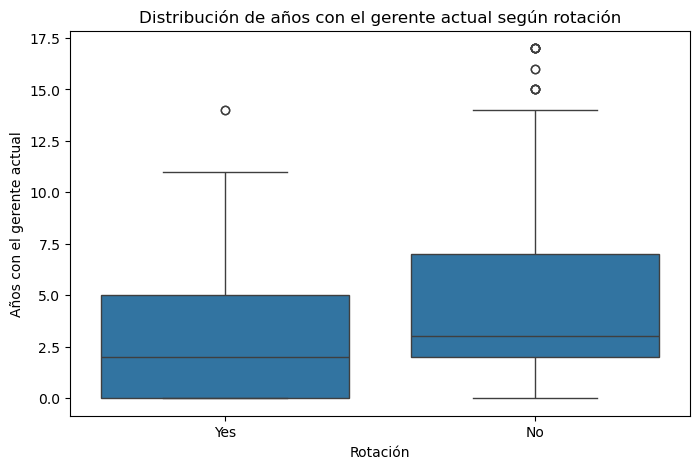

In [53]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="YearsWithCurrManager"
)

plt.title("Distribución de años con el gerente actual según rotación")
plt.xlabel("Rotación")
plt.ylabel("Años con el gerente actual")

plt.show()

### Hallazgo: antigüedad con el gerente actual y rotación

La antigüedad con el gerente actual presenta diferencias entre los empleados que permanecieron y aquellos que presentaron rotación. El promedio fue de **4,37 años** entre quienes permanecieron y de **2,85 años** entre quienes salieron.

La mediana también fue ligeramente mayor entre quienes permanecieron (**3 años frente a 2 años**). Además, el primer cuartil fue de **2 años** para quienes permanecieron y de **0 años** para quienes presentaron rotación.

Estos resultados muestran una **asociación entre una menor antigüedad con el gerente actual y una mayor rotación observada** en este conjunto de datos. Sin embargo, no permiten establecer que la relación con el gerente sea la causa de la rotación.


In [54]:
df_analysis.groupby("Attrition")["JobInvolvement"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,2.770479,0.692050,1.0,2.0,3.0,3.0,4.0
Yes,237.0,2.518987,0.773405,1.0,2.0,3.0,3.0,4.0


In [55]:
df_analysis.groupby("Attrition")["RelationshipSatisfaction"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,2.733982,1.071603,1.0,2.0,3.0,4.0,4.0
Yes,237.0,2.599156,1.125437,1.0,2.0,3.0,4.0,4.0


In [56]:
df_analysis.groupby("Attrition")["PerformanceRating"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,3.153285,0.360408,3.0,3.0,3.0,3.0,4.0
Yes,237.0,3.156118,0.363735,3.0,3.0,3.0,3.0,4.0


In [57]:
df_analysis.groupby("Attrition")["PercentSalaryHike"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,15.231144,3.639511,11.0,12.0,14.0,18.0,25.0
Yes,237.0,15.097046,3.770294,11.0,12.0,14.0,17.0,25.0


In [58]:
df_analysis.groupby("Attrition")["YearsSinceLastPromotion"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,2.234388,3.234762,0.0,0.0,1.0,3.0,15.0
Yes,237.0,1.945148,3.153077,0.0,0.0,1.0,2.0,15.0


In [59]:
attrition_rate_by("MaritalStatus")

,MaritalStatus,AttritionRate
2,Single,25.531915
1,Married,12.481426
0,Divorced,10.091743


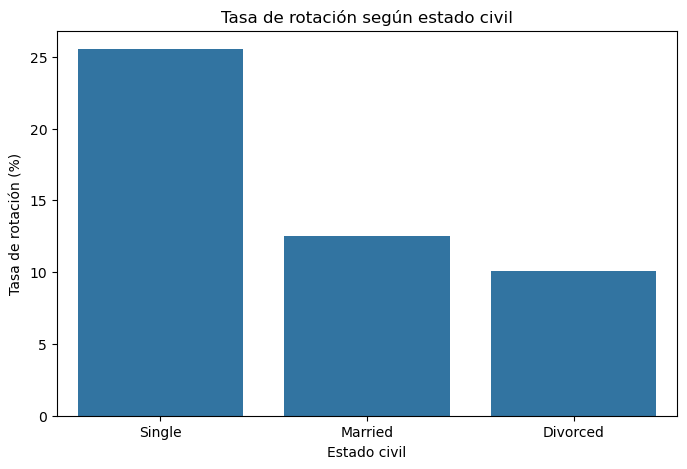

In [60]:
marital_attrition = attrition_rate_by("MaritalStatus")

plt.figure(figsize=(8, 5))

sns.barplot(
    data=marital_attrition,
    x="MaritalStatus",
    y="AttritionRate"
)

plt.title("Tasa de rotación según estado civil")
plt.xlabel("Estado civil")
plt.ylabel("Tasa de rotación (%)")

plt.show()

### Hallazgo inicial: estado civil y rotación

La tasa de rotación observada presenta diferencias según el estado civil. Los empleados **solteros** presentan la tasa más alta, con **25,53 %**, frente a **12,48 %** entre los empleados casados y **10,09 %** entre los empleados divorciados.

En este conjunto de datos, el estado civil presenta una asociación con la rotación observada. Sin embargo, esta diferencia no permite establecer que el estado civil sea la causa de la rotación.


In [61]:
attrition_rate_by("EducationField")

,EducationField,AttritionRate
0,Human Resources,25.925926
5,Technical Degree,24.242424
2,Marketing,22.012579
1,Life Sciences,14.686469
3,Medical,13.577586
4,Other,13.414634


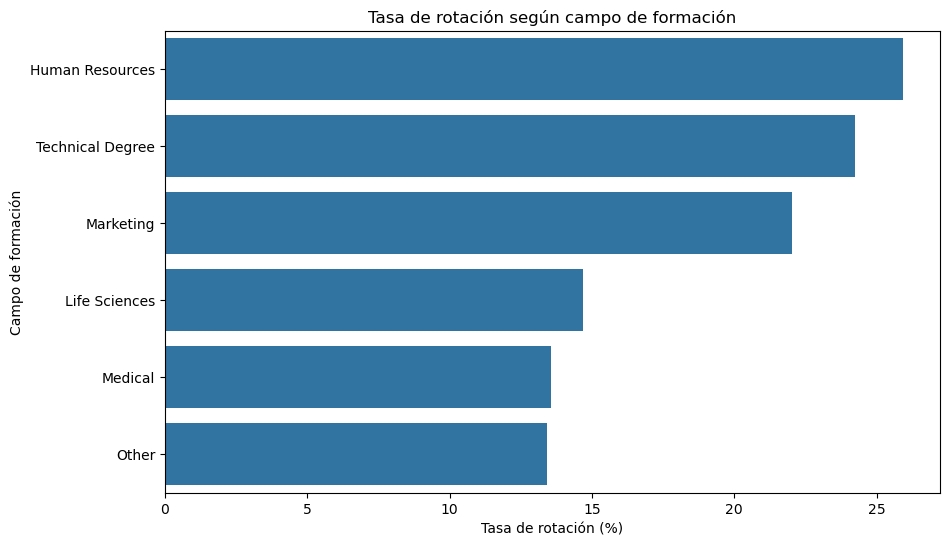

In [62]:
education_attrition = attrition_rate_by("EducationField")

plt.figure(figsize=(10, 6))

sns.barplot(
    data=education_attrition,
    x="AttritionRate",
    y="EducationField"
)

plt.title("Tasa de rotación según campo de formación")
plt.xlabel("Tasa de rotación (%)")
plt.ylabel("Campo de formación")

plt.show()

### Hallazgo inicial: campo de formación y rotación

La tasa de rotación observada presenta diferencias según el campo de formación de los empleados. Las tasas más altas corresponden a **Human Resources (25,93 %)**, **Technical Degree (24,24 %)** y **Marketing (22,01 %)**.

En contraste, **Other (13,41 %)**, **Medical (13,58 %)** y **Life Sciences (14,69 %)** presentan tasas de rotación observadas más bajas.

Estas diferencias muestran una asociación entre el campo de formación y la rotación en este conjunto de datos. Sin embargo, no permiten establecer que el campo de formación sea la causa de la rotación.


In [63]:
attrition_rate_by("Gender")

,Gender,AttritionRate
1,Male,17.006803
0,Female,14.795918


In [64]:
attrition_rate_by("Education")

,Education,AttritionRate
0,1,18.235294
2,3,17.307692
1,2,15.602837
3,4,14.572864
4,5,10.416667


In [65]:
travel_marital = (
    pd.crosstab(
        df_analysis["MaritalStatus"],
        df_analysis["BusinessTravel"],
        values=df_analysis["Attrition"],
        aggfunc=lambda x: (x == "Yes").mean() * 100
    )
    .reset_index()
)

travel_marital

BusinessTravel,MaritalStatus,Non-Travel,Travel_Frequently,Travel_Rarely
0,Divorced,2.272727,20.634921,8.636364
1,Married,5.084746,16.101695,12.500000
2,Single,17.021277,38.541667,22.935780


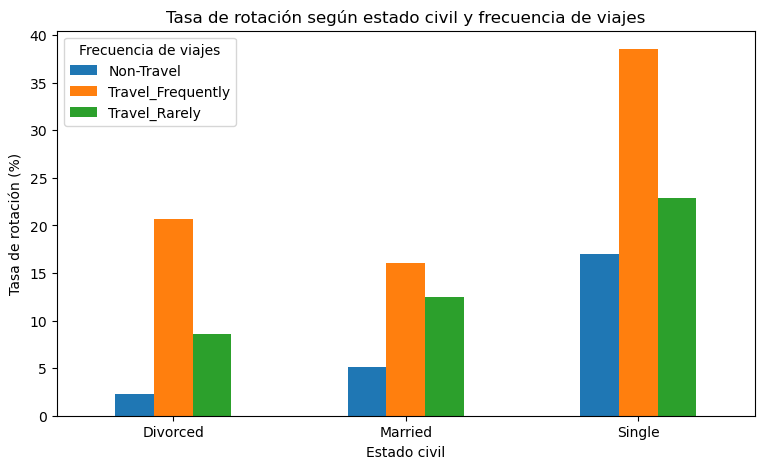

In [66]:
travel_marital.plot(
    x="MaritalStatus",
    kind="bar",
    figsize=(9, 5)
)

plt.title("Tasa de rotación según estado civil y frecuencia de viajes")
plt.xlabel("Estado civil")
plt.ylabel("Tasa de rotación (%)")
plt.xticks(rotation=0)
plt.legend(title="Frecuencia de viajes")

plt.show()

### Hallazgo: frecuencia de viajes, estado civil y rotación

Al analizar conjuntamente el estado civil y la frecuencia de viajes, se observan diferencias en las tasas de rotación.

La diferencia es especialmente visible entre los empleados **solteros**: la tasa de rotación observada fue de **17,02 %** entre quienes no viajaban, **22,94 %** entre quienes viajaban rara vez y **38,54 %** entre quienes viajaban frecuentemente.

Entre los empleados casados y divorciados también se observa una mayor tasa de rotación entre quienes viajaban frecuentemente en comparación con quienes no viajaban.

Este análisis muestra que la asociación observada entre frecuencia de viajes y rotación varía según el estado civil. Sin embargo, estos resultados no permiten establecer una relación causal entre estas variables y la rotación.


In [67]:
attrition_rate_by("JobRole")

,JobRole,AttritionRate
8,Sales Representative,39.759036
2,Laboratory Technician,23.938224
1,Human Resources,23.076923
7,Sales Executive,17.484663
6,Research Scientist,16.095890
4,Manufacturing Director,6.896552
0,Healthcare Representative,6.870229
3,Manager,4.901961
5,Research Director,2.500000


In [68]:
df_analysis.groupby("Attrition")["MonthlyRate"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,14265.779400,7102.260749,2094.0,7973.0,14120.0,20364.0,26997.0
Yes,237.0,14559.308017,7208.153264,2326.0,8870.0,14618.0,21081.0,26999.0


In [69]:
df_analysis.groupby("Attrition")["HourlyRate"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,65.952149,20.380754,30.0,48.0,66.0,83.0,100.0
Yes,237.0,65.573840,20.099958,31.0,50.0,66.0,84.0,100.0


In [70]:
df_analysis.groupby("Attrition")["DailyRate"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,812.504461,403.208379,102.0,477.0,817.0,1176.0,1499.0
Yes,237.0,750.362869,401.899519,103.0,408.0,699.0,1092.0,1496.0


In [71]:
df_analysis.groupby("Attrition")["TotalWorkingYears"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,11.862936,7.760719,0.0,6.0,10.0,16.0,38.0
Yes,237.0,8.244726,7.169204,0.0,3.0,7.0,10.0,40.0


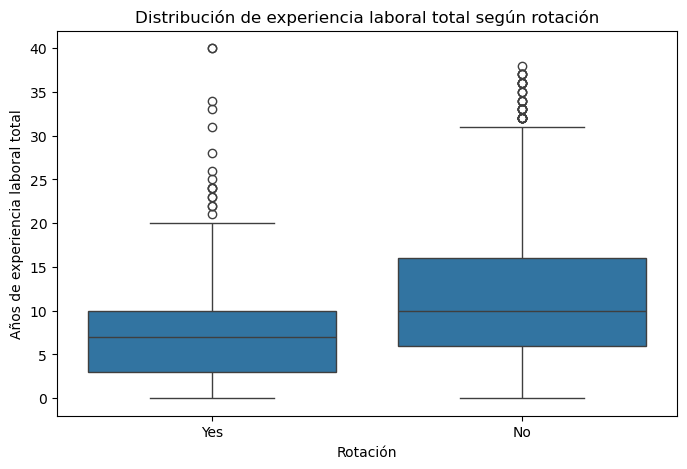

In [72]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="TotalWorkingYears"
)

plt.title("Distribución de experiencia laboral total según rotación")
plt.xlabel("Rotación")
plt.ylabel("Años de experiencia laboral total")

plt.show()

### Hallazgo inicial: experiencia laboral total y rotación

La experiencia laboral total presenta diferencias entre los empleados que permanecieron y aquellos que presentaron rotación. El promedio fue de **11,86 años** entre quienes permanecieron y de **8,24 años** entre quienes salieron.

La diferencia también se observa en la mediana: **10 años** de experiencia entre quienes permanecieron frente a **7 años** entre quienes presentaron rotación. Además, el tercer cuartil fue de **16 años** para quienes permanecieron y de **10 años** para quienes salieron.

Estos resultados muestran una **asociación entre una menor experiencia laboral total y una mayor rotación observada** en este conjunto de datos. Sin embargo, no permiten establecer que la experiencia laboral sea la causa de la rotación.


In [73]:
numeric_variables = [
    "Age",
    "MonthlyIncome",
    "YearsAtCompany",
    "JobSatisfaction",
    "EnvironmentSatisfaction",
    "WorkLifeBalance",
    "JobLevel",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "TrainingTimesLastYear",
    "NumCompaniesWorked",
    "DistanceFromHome",
    "MonthlyRate",
    "HourlyRate",
    "DailyRate",
    "TotalWorkingYears",
    "YearsWithCurrManager",
    "JobInvolvement",
    "RelationshipSatisfaction",
    "PerformanceRating",
    "PercentSalaryHike"
]

summary_numeric = (
    df_analysis.groupby("Attrition")[numeric_variables]
    .mean()
    .T
    .reset_index()
    .rename(columns={"index": "Variable"})
)

summary_numeric["Difference"] = (
    summary_numeric["Yes"] - summary_numeric["No"]
)

summary_numeric

Attrition,Variable,No,Yes,Difference
0,Age,37.561233,33.607595,-3.953638
1,MonthlyIncome,6832.739659,4787.092827,-2045.646832
2,YearsAtCompany,7.369019,5.130802,-2.238217
3,JobSatisfaction,2.778589,2.468354,-0.310234
4,EnvironmentSatisfaction,2.771290,2.464135,-0.307155
5,WorkLifeBalance,2.781022,2.658228,-0.122794
6,JobLevel,2.145985,1.637131,-0.508855
7,YearsInCurrentRole,4.484185,2.902954,-1.581231
8,YearsSinceLastPromotion,2.234388,1.945148,-0.289240
9,TrainingTimesLastYear,2.832928,2.624473,-0.208455


In [74]:
summary_numeric["AbsoluteDifference"] = summary_numeric["Difference"].abs()

summary_numeric.sort_values(
    "AbsoluteDifference",
    ascending=False
)

Attrition,Variable,No,Yes,Difference,AbsoluteDifference
1,MonthlyIncome,6832.739659,4787.092827,-2045.646832,2045.646832
12,MonthlyRate,14265.779400,14559.308017,293.528617,293.528617
14,DailyRate,812.504461,750.362869,-62.141591,62.141591
0,Age,37.561233,33.607595,-3.953638,3.953638
15,TotalWorkingYears,11.862936,8.244726,-3.618210,3.618210
2,YearsAtCompany,7.369019,5.130802,-2.238217,2.238217
11,DistanceFromHome,8.915653,10.632911,1.717259,1.717259
7,YearsInCurrentRole,4.484185,2.902954,-1.581231,1.581231
16,YearsWithCurrManager,4.367397,2.852321,-1.515076,1.515076
6,JobLevel,2.145985,1.637131,-0.508855,0.508855


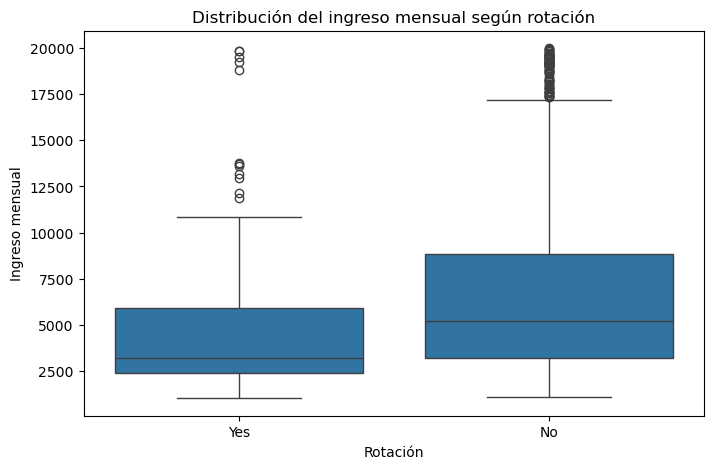

In [75]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="MonthlyIncome"
)

plt.title("Distribución del ingreso mensual según rotación")
plt.xlabel("Rotación")
plt.ylabel("Ingreso mensual")

plt.show()

### Hallazgo inicial: ingreso mensual y rotación

El ingreso mensual presenta diferencias entre los empleados que permanecieron y aquellos que presentaron rotación. El ingreso promedio fue de **6.832,74** entre quienes permanecieron y de **4.787,09** entre quienes salieron.

La diferencia también se observa en la mediana: **5.204** para quienes permanecieron frente a **3.202** para quienes presentaron rotación. Además, el tercer cuartil fue de **8.834** para el grupo sin rotación y de **5.916** para el grupo con rotación.

Estos resultados muestran una **asociación entre un menor ingreso mensual y una mayor rotación observada** en este conjunto de datos. Sin embargo, no permiten establecer que el ingreso sea la causa de la rotación.


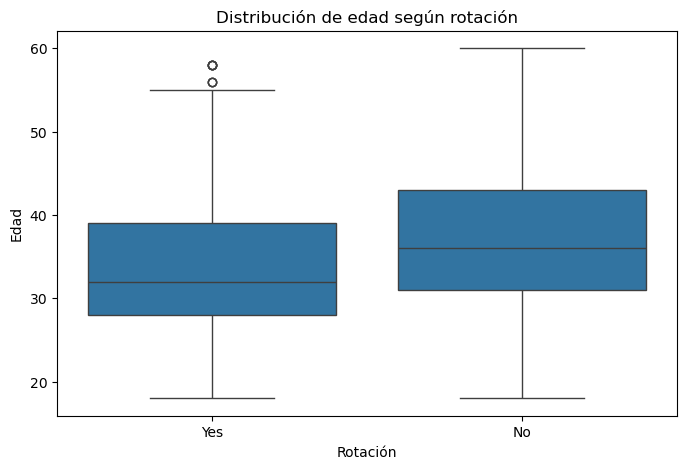

In [76]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="Age"
)

plt.title("Distribución de edad según rotación")
plt.xlabel("Rotación")
plt.ylabel("Edad")

plt.show()

### Hallazgo inicial: edad y rotación

La edad presenta diferencias entre los empleados que permanecieron y aquellos que presentaron rotación. La edad promedio fue de **37,56 años** entre quienes permanecieron y de **33,61 años** entre quienes salieron.

La diferencia también se observa en la mediana: **36 años** para quienes permanecieron frente a **32 años** para quienes presentaron rotación. Además, el primer y tercer cuartil fueron menores en el grupo con rotación.

Estos resultados muestran una **asociación entre una menor edad y una mayor rotación observada** en este conjunto de datos. Sin embargo, no permiten establecer que la edad sea la causa de la rotación.


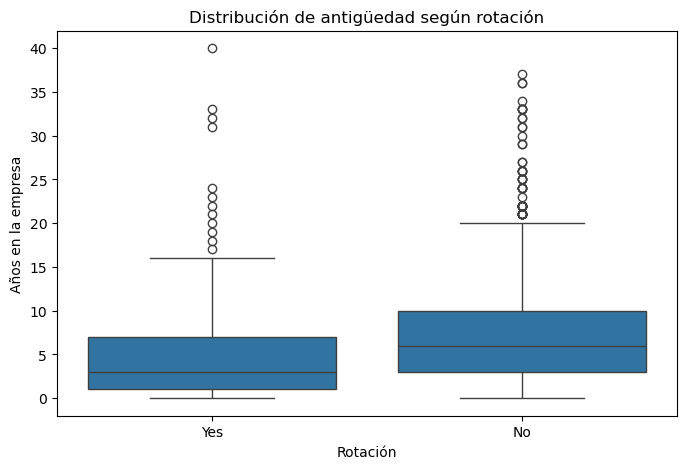

In [77]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="YearsAtCompany"
)

plt.title("Distribución de antigüedad según rotación")
plt.xlabel("Rotación")
plt.ylabel("Años en la empresa")

plt.show()

### Hallazgo inicial: antigüedad en la empresa y rotación

La antigüedad en la empresa presenta diferencias entre los empleados que permanecieron y aquellos que presentaron rotación. La antigüedad promedio fue de **7,37 años** entre quienes permanecieron y de **5,13 años** entre quienes salieron.

La diferencia también se observa en la mediana: **6 años** para quienes permanecieron frente a **3 años** para quienes presentaron rotación. Además, el primer y tercer cuartil fueron menores en el grupo con rotación.

Estos resultados muestran una **asociación entre una menor antigüedad en la empresa y una mayor rotación observada** en este conjunto de datos. Sin embargo, no permiten establecer que la antigüedad sea la causa de la rotación.


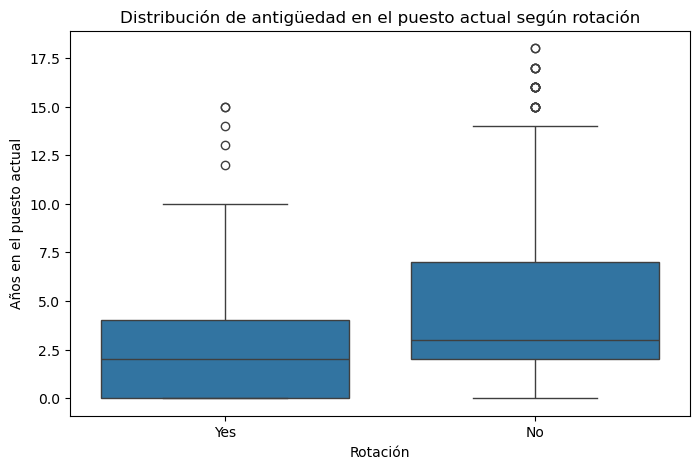

In [78]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="YearsInCurrentRole"
)

plt.title("Distribución de antigüedad en el puesto actual según rotación")
plt.xlabel("Rotación")
plt.ylabel("Años en el puesto actual")

plt.show()

### Hallazgo inicial: antigüedad en el puesto actual y rotación

La antigüedad en el puesto actual presenta diferencias entre los empleados que permanecieron y aquellos que presentaron rotación. El promedio fue de **4,48 años** entre quienes permanecieron y de **2,90 años** entre quienes salieron.

La mediana también fue menor en el grupo con rotación: **2 años**, frente a **3 años** entre quienes permanecieron. Además, el primer cuartil fue de **0 años** para quienes salieron y de **2 años** para quienes permanecieron.

Estos resultados muestran una **asociación entre una menor antigüedad en el puesto actual y una mayor rotación observada** en este conjunto de datos, pero no permiten establecer una relación causal.


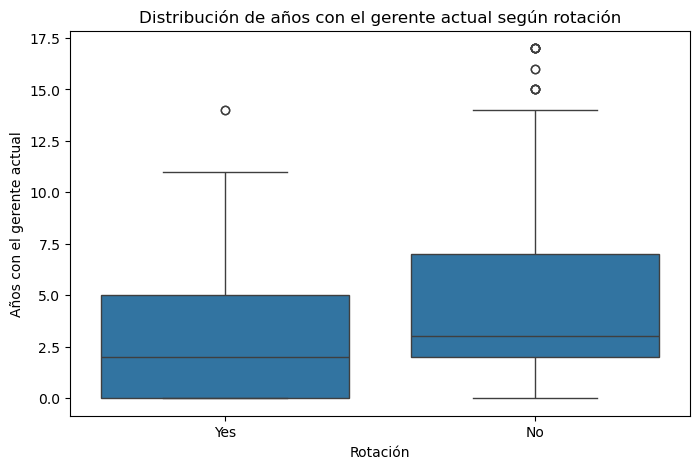

In [79]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="YearsWithCurrManager"
)

plt.title("Distribución de años con el gerente actual según rotación")
plt.xlabel("Rotación")
plt.ylabel("Años con el gerente actual")

plt.show()

### Hallazgo inicial: antigüedad con el gerente actual y rotación

La antigüedad con el gerente actual presenta diferencias entre los empleados que permanecieron y aquellos que presentaron rotación. El promedio fue de **4,37 años** entre quienes permanecieron y de **2,85 años** entre quienes salieron.

La mediana también fue ligeramente mayor entre quienes permanecieron (**3 años frente a 2 años**). Además, el primer cuartil fue de **2 años** para quienes permanecieron y de **0 años** para quienes presentaron rotación.

Estos resultados muestran una **asociación entre una menor antigüedad con el gerente actual y una mayor rotación observada** en este conjunto de datos. Sin embargo, no permiten establecer que la relación con el gerente sea la causa de la rotación.


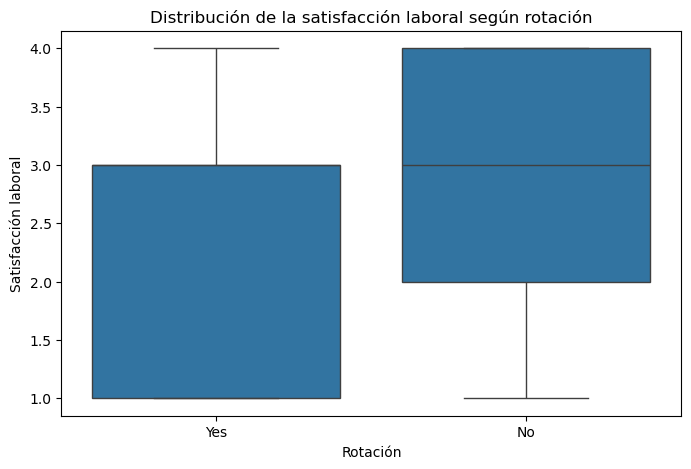

In [80]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="JobSatisfaction"
)

plt.title("Distribución de la satisfacción laboral según rotación")
plt.xlabel("Rotación")
plt.ylabel("Satisfacción laboral")

plt.show()

### Hallazgo inicial: satisfacción laboral y rotación

La satisfacción laboral promedio es menor entre los empleados que presentaron rotación (**2,47**) que entre quienes permanecieron (**2,78**).

Aunque la mediana fue de **3** en ambos grupos, la distribución presenta valores inferiores entre quienes presentaron rotación: el primer cuartil fue de **1**, frente a **2** entre quienes permanecieron, y el tercer cuartil fue de **3**, frente a **4**.

Estos resultados muestran una **asociación entre una menor satisfacción laboral y una mayor rotación observada** en este conjunto de datos. Sin embargo, la diferencia descriptiva es moderada y no permite establecer una relación causal.


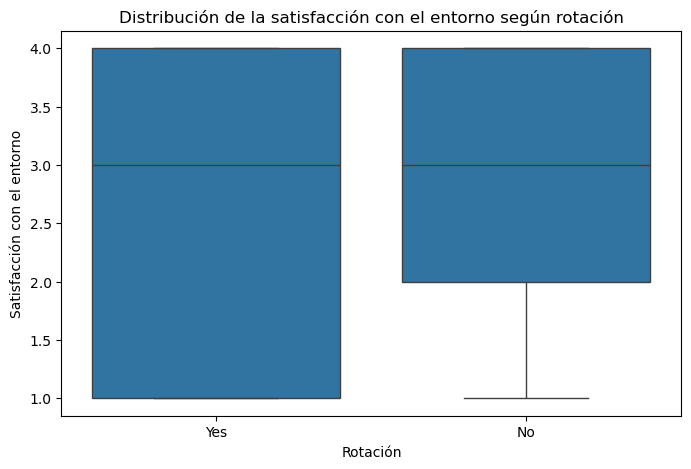

In [81]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="EnvironmentSatisfaction"
)

plt.title("Distribución de la satisfacción con el entorno según rotación")
plt.xlabel("Rotación")
plt.ylabel("Satisfacción con el entorno")

plt.show()

### Hallazgo inicial: satisfacción con el entorno y rotación

La satisfacción con el entorno laboral presenta diferencias entre los empleados que permanecieron y aquellos que presentaron rotación. El promedio fue de **2,77** entre quienes permanecieron y de **2,46** entre quienes salieron.

La mediana fue de **3** en ambos grupos. Sin embargo, el primer cuartil fue de **2** entre quienes permanecieron y de **1** entre quienes presentaron rotación.

Estos resultados muestran una **asociación entre una menor satisfacción con el entorno laboral y una mayor rotación observada** en este conjunto de datos. La diferencia descriptiva es moderada y no permite establecer una relación causal.


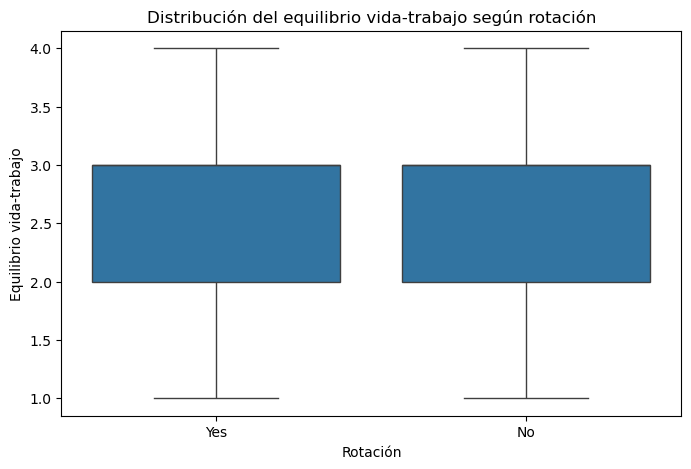

In [82]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_analysis,
    x="Attrition",
    y="WorkLifeBalance"
)

plt.title("Distribución del equilibrio vida-trabajo según rotación")
plt.xlabel("Rotación")
plt.ylabel("Equilibrio vida-trabajo")

plt.show()

### Hallazgo inicial: equilibrio vida-trabajo y rotación

El equilibrio entre vida laboral y personal presenta una diferencia pequeña entre los dos grupos. El promedio fue de **2,78** entre quienes permanecieron y de **2,66** entre quienes presentaron rotación.

La mediana fue de **3** en ambos grupos, al igual que el primer y tercer cuartil (**2 y 3**, respectivamente).

En este conjunto de datos, la diferencia descriptiva en `WorkLifeBalance` es menor que la observada en otras variables analizadas. Por lo tanto, esta variable no presenta una diferencia particularmente marcada entre los grupos de rotación y permanencia.


### Hallazgo: satisfacción laboral, horas extra y rotación

Al analizar conjuntamente la satisfacción laboral y las horas extra, la tasa de rotación observada fue mayor entre los empleados que trabajaban horas extra en **todos los niveles de satisfacción laboral**.

La diferencia fue especialmente visible en los niveles de satisfacción **2 y 3**, donde la tasa de rotación fue de **37,68 %** y **33,88 %**, respectivamente, entre quienes trabajaban horas extra, frente a **9,48 %** y **9,97 %** entre quienes no trabajaban horas extra.

Incluso entre los empleados con el nivel más alto de satisfacción laboral (4), la tasa de rotación observada fue mayor cuando existían horas extra: **21,13 % frente a 6,94 %**.

Este resultado muestra una asociación observada entre las horas extra y la rotación dentro de los distintos niveles de satisfacción laboral en este conjunto de datos. Sin embargo, no permite establecer una relación causal.


In [83]:
df_corr = df_analysis.copy()

df_corr["AttritionBinary"] = (
    df_corr["Attrition"] == "Yes"
).astype(int)

df_corr[["Attrition", "AttritionBinary"]].head()

,Attrition,AttritionBinary
0,Yes,1
1,No,0
2,Yes,1
3,No,0
4,No,0


In [84]:
correlation_with_attrition = (
    df_corr[numeric_variables + ["AttritionBinary"]]
    .corr()["AttritionBinary"]
    .drop("AttritionBinary")
    .sort_values()
)

correlation_with_attrition

TotalWorkingYears          -0.171063
JobLevel                   -0.169105
YearsInCurrentRole         -0.160545
MonthlyIncome              -0.159840
Age                        -0.159205
YearsWithCurrManager       -0.156199
YearsAtCompany             -0.134392
JobInvolvement             -0.130016
JobSatisfaction            -0.103481
EnvironmentSatisfaction    -0.103369
WorkLifeBalance            -0.063939
TrainingTimesLastYear      -0.059478
DailyRate                  -0.056652
RelationshipSatisfaction   -0.045872
YearsSinceLastPromotion    -0.033019
PercentSalaryHike          -0.013478
HourlyRate                 -0.006846
PerformanceRating           0.002889
MonthlyRate                 0.015170
NumCompaniesWorked          0.043494
DistanceFromHome            0.077924
Name: AttritionBinary, dtype: float64

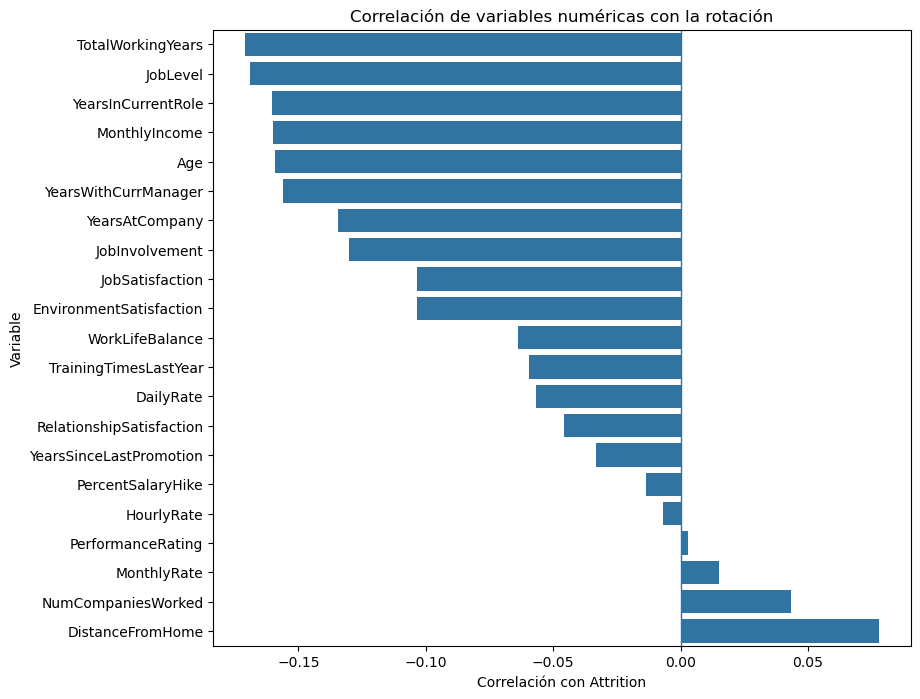

In [85]:
plt.figure(figsize=(9, 8))

sns.barplot(
    x=correlation_with_attrition.values,
    y=correlation_with_attrition.index
)

plt.title("Correlación de variables numéricas con la rotación")
plt.xlabel("Correlación con Attrition")
plt.ylabel("Variable")

plt.axvline(0, linewidth=1)

plt.show()

### Hallazgo: correlación de variables numéricas con la rotación

El análisis de correlación muestra asociaciones de magnitud baja entre las variables numéricas y `AttritionBinary`. Las correlaciones negativas más altas corresponden a **TotalWorkingYears (-0,171)**, **JobLevel (-0,169)**, **YearsInCurrentRole (-0,161)**, **MonthlyIncome (-0,160)**, **Age (-0,159)** y **YearsWithCurrManager (-0,156)**.

Esto indica que, en este conjunto de datos, valores más altos en estas variables tienden a estar asociados con una menor presencia de rotación. Sin embargo, la magnitud de las correlaciones es baja y una correlación por sí sola no permite establecer causalidad.

También se observan variables con una asociación lineal prácticamente nula, como **PerformanceRating (0,003)**, **HourlyRate (-0,007)** y **PercentSalaryHike (-0,013)**.

En conjunto, estos resultados sugieren que la rotación no puede explicarse mediante una sola variable numérica y justifican continuar el análisis considerando **múltiples variables de manera conjunta**.


In [86]:
X = df_analysis.drop(columns=["Attrition"])

y = (df_analysis["Attrition"] == "Yes").astype(int)

X.shape, y.shape

((1470, 31), (1470,))

In [87]:
df_analysis = df.copy()

columns_to_drop = [
    "EmployeeCount",
    "Over18",
    "StandardHours"
]

df_analysis = df_analysis.drop(columns=columns_to_drop)

df_analysis.shape

(1470, 32)

In [88]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numeric_features = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Variables categóricas:")
print(categorical_features)

print("\nNúmero de variables categóricas:", len(categorical_features))

print("\nNúmero de variables numéricas:", len(numeric_features))

Variables categóricas:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Número de variables categóricas: 7

Número de variables numéricas: 24


In [89]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [90]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1176, 31), (294, 31), (1176,), (294,))

In [91]:
X_train = X_train.drop(columns=["EmployeeNumber"])
X_test = X_test.drop(columns=["EmployeeNumber"])

X_train.shape, X_test.shape

((1176, 30), (294, 30))

In [92]:
numeric_features = [
    column for column in numeric_features
    if column != "EmployeeNumber"
]

len(numeric_features), numeric_features

(23,
 ['Age',
  'DailyRate',
  'DistanceFromHome',
  'Education',
  'EnvironmentSatisfaction',
  'HourlyRate',
  'JobInvolvement',
  'JobLevel',
  'JobSatisfaction',
  'MonthlyIncome',
  'MonthlyRate',
  'NumCompaniesWorked',
  'PercentSalaryHike',
  'PerformanceRating',
  'RelationshipSatisfaction',
  'StockOptionLevel',
  'TotalWorkingYears',
  'TrainingTimesLastYear',
  'WorkLifeBalance',
  'YearsAtCompany',
  'YearsInCurrentRole',
  'YearsSinceLastPromotion',
  'YearsWithCurrManager'])

In [93]:
from sklearn.preprocessing import StandardScaler

In [123]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_features
        )
    ]
)

In [124]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

X_train_processed.shape, X_test_processed.shape

((1176, 44), (294, 44))

In [109]:
from sklearn.linear_model import LogisticRegression

In [125]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [126]:
model.fit(X_train_processed, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [127]:
y_pred = model.predict(X_test_processed)

y_pred[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [128]:
from sklearn.metrics import confusion_matrix

In [129]:
cm = confusion_matrix(y_test, y_pred)

cm

array([[238,   9],
       [ 31,  16]])

In [130]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.96      0.92       247
           1       0.64      0.34      0.44        47

    accuracy                           0.86       294
   macro avg       0.76      0.65      0.68       294
weighted avg       0.85      0.86      0.85       294



In [131]:
y_prob = model.predict_proba(X_test_processed)[:, 1]

y_prob[:10]

array([0.0974376 , 0.00289232, 0.182142  , 0.0045899 , 0.29854287,
       0.25321261, 0.00800043, 0.01506742, 0.00374778, 0.11561723])

In [132]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, y_prob)

roc_auc

np.float64(0.8102334395727453)

In [133]:
roc_auc = roc_auc_score(y_test, y_prob)

roc_auc

np.float64(0.8102334395727453)

In [138]:
feature_names = preprocessor.get_feature_names_out()

feature_names

array(['categorical__BusinessTravel_Travel_Frequently',
       'categorical__BusinessTravel_Travel_Rarely',
       'categorical__Department_Research & Development',
       'categorical__Department_Sales',
       'categorical__EducationField_Life Sciences',
       'categorical__EducationField_Marketing',
       'categorical__EducationField_Medical',
       'categorical__EducationField_Other',
       'categorical__EducationField_Technical Degree',
       'categorical__Gender_Male', 'categorical__JobRole_Human Resources',
       'categorical__JobRole_Laboratory Technician',
       'categorical__JobRole_Manager',
       'categorical__JobRole_Manufacturing Director',
       'categorical__JobRole_Research Director',
       'categorical__JobRole_Research Scientist',
       'categorical__JobRole_Sales Executive',
       'categorical__JobRole_Sales Representative',
       'categorical__MaritalStatus_Married',
       'categorical__MaritalStatus_Single', 'categorical__OverTime_Yes',
       'numer

In [142]:
coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": model.coef_[0]
})

coefficients = coefficients.sort_values(
    "Coefficient",
    ascending=False
)

coefficients

,Feature,Coefficient
20,categorical__OverTime_Yes,1.796364
0,categorical__BusinessTravel_Travel_Frequently,1.549427
11,categorical__JobRole_Laboratory Technician,1.313674
17,categorical__JobRole_Sales Representative,0.957632
19,categorical__MaritalStatus_Single,0.684678
1,categorical__BusinessTravel_Travel_Rarely,0.679433
10,categorical__JobRole_Human Resources,0.528949
42,numeric__YearsSinceLastPromotion,0.520141
32,numeric__NumCompaniesWorked,0.480890
23,numeric__DistanceFromHome,0.375241


In [143]:
model.coef_.shape

(1, 44)

In [144]:
X_train_processed.shape

(1176, 44)

In [145]:
coefficients["OddsRatio"] = np.exp(coefficients["Coefficient"])

coefficients

,Feature,Coefficient,OddsRatio
20,categorical__OverTime_Yes,1.796364,6.027692
0,categorical__BusinessTravel_Travel_Frequently,1.549427,4.708772
11,categorical__JobRole_Laboratory Technician,1.313674,3.719817
17,categorical__JobRole_Sales Representative,0.957632,2.605518
19,categorical__MaritalStatus_Single,0.684678,1.983133
1,categorical__BusinessTravel_Travel_Rarely,0.679433,1.972759
10,categorical__JobRole_Human Resources,0.528949,1.697148
42,numeric__YearsSinceLastPromotion,0.520141,1.682265
32,numeric__NumCompaniesWorked,0.480890,1.617514
23,numeric__DistanceFromHome,0.375241,1.455342


In [147]:
y_pred = model.predict(X_test_processed)
y_prob = model.predict_proba(X_test_processed)[:, 1]

In [148]:
y_pred[:10], y_prob[:10]

(array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0]),
 array([0.0974376 , 0.00289232, 0.182142  , 0.0045899 , 0.29854287,
        0.25321261, 0.00800043, 0.01506742, 0.00374778, 0.11561723]))

In [149]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
cm

array([[238,   9],
       [ 31,  16]])

In [150]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.96      0.92       247
           1       0.64      0.34      0.44        47

    accuracy                           0.86       294
   macro avg       0.76      0.65      0.68       294
weighted avg       0.85      0.86      0.85       294



In [151]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, y_prob)
roc_auc

np.float64(0.8102334395727453)

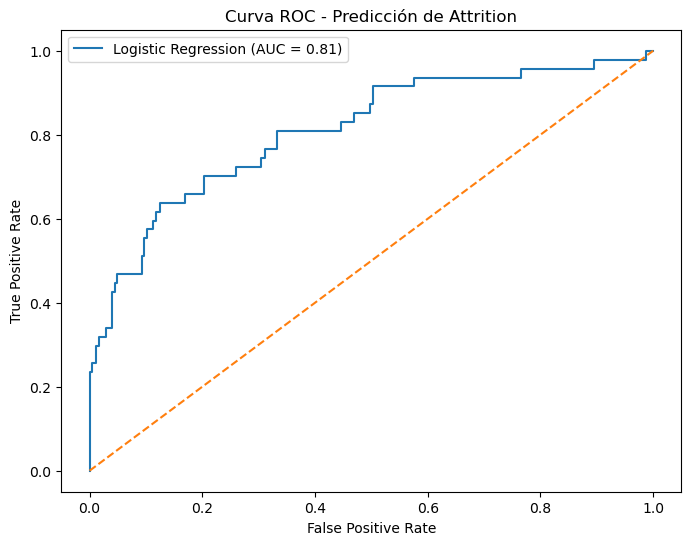

In [152]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("Curva ROC - Predicción de Attrition")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

In [153]:
threshold = 0.30

y_pred_30 = (y_prob >= threshold).astype(int)

print(classification_report(y_test, y_pred_30))

              precision    recall  f1-score   support

           0       0.91      0.90      0.90       247
           1       0.50      0.51      0.51        47

    accuracy                           0.84       294
   macro avg       0.70      0.71      0.70       294
weighted avg       0.84      0.84      0.84       294



In [154]:
thresholds_to_test = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

threshold_results = []

for threshold in thresholds_to_test:
    y_pred_threshold = (y_prob >= threshold).astype(int)
    
    report = classification_report(
        y_test,
        y_pred_threshold,
        output_dict=True
    )
    
    threshold_results.append({
        "Threshold": threshold,
        "Precision": report["1"]["precision"],
        "Recall": report["1"]["recall"],
        "F1": report["1"]["f1-score"],
        "Accuracy": report["accuracy"]
    })

threshold_results = pd.DataFrame(threshold_results)

threshold_results

,Threshold,Precision,Recall,F1,Accuracy
0,0.20,0.428571,0.638298,0.512821,0.806122
1,0.25,0.483871,0.638298,0.550459,0.833333
2,0.30,0.500000,0.510638,0.505263,0.840136
3,0.35,0.536585,0.468085,0.500000,0.850340
4,0.40,0.645161,0.425532,0.512821,0.870748
5,0.45,0.655172,0.404255,0.500000,0.870748
6,0.50,0.640000,0.340426,0.444444,0.863946


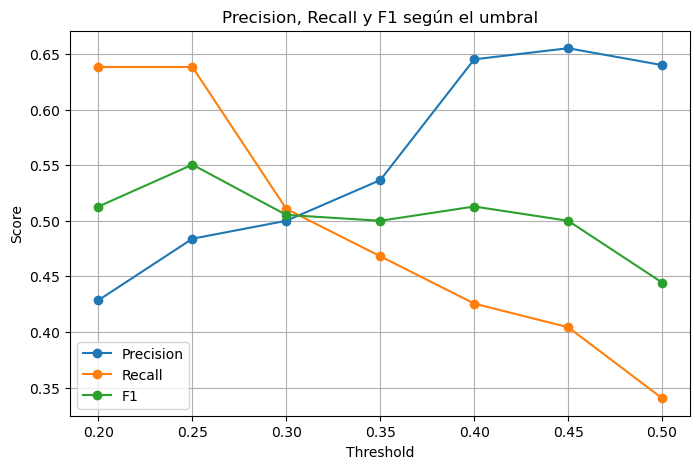

In [155]:
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1"],
    marker="o",
    label="F1"
)

plt.title("Precision, Recall y F1 según el umbral")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()

### Evaluación del modelo y ajuste del umbral

La regresión logística obtuvo un **ROC-AUC de 0,81** en el conjunto de prueba, lo que indica una capacidad razonable para distinguir entre empleados con y sin rotación en este conjunto de datos.

Con el umbral predeterminado de **0,50**, el modelo obtuvo una precisión de **0,64** y un recall de **0,34** para la clase `Attrition = Yes`. Esto significa que el modelo identificó correctamente una parte limitada de los casos reales de rotación.

Al reducir el umbral a **0,30**, el recall aumentó a **0,51**, mientras que la precisión disminuyó a **0,50**. En los umbrales evaluados, el F1 alcanzó su valor más alto (**0,51**) en 0,30.

Este comportamiento muestra el equilibrio entre detectar una mayor proporción de posibles casos de rotación y generar un mayor número de falsos positivos. Por lo tanto, la selección del umbral debe depender del objetivo de negocio y del costo relativo de cada tipo de error.

El modelo debe interpretarse como una herramienta de apoyo para identificar patrones y posibles casos de interés, y no como una predicción determinista de que un empleado abandonará la organización.

# Conclusiones del análisis

El análisis permitió identificar diferentes patrones asociados con la rotación de empleados en este conjunto de datos.

Entre los principales hallazgos se encuentran:

- Los empleados que realizan **horas extra (`OverTime = Yes`)** presentan una tasa de rotación observada considerablemente mayor que quienes no realizan horas extra.
- La frecuencia de **viajes de trabajo** también muestra diferencias en la tasa de rotación, especialmente entre quienes viajan frecuentemente y quienes no viajan.
- La tasa de rotación varía considerablemente según el **rol del empleado**, con diferencias particularmente marcadas entre algunos roles.
- Los empleados que presentaron rotación muestran, en promedio, **menor edad**, **menor ingreso mensual** y **menor antigüedad en la empresa**.
- También se observaron diferencias en variables relacionadas con la experiencia del empleado, como **JobSatisfaction**, **EnvironmentSatisfaction**, **YearsInCurrentRole** y **YearsWithCurrManager**.
- La matriz de correlaciones mostró que ninguna variable numérica, por sí sola, presenta una relación lineal suficientemente fuerte como para explicar la rotación.
- El modelo de **Regresión Logística**, al considerar múltiples variables simultáneamente, obtuvo un **ROC-AUC de 0,81** en el conjunto de prueba.

En conjunto, los resultados sugieren que la rotación está asociada con una combinación de factores relacionados con las **condiciones de trabajo, movilidad, características del puesto, experiencia laboral y satisfacción del empleado**.

Estos resultados representan asociaciones observadas en el conjunto de datos y **no permiten establecer relaciones de causalidad**.

# Recomendaciones para People Analytics

A partir de los patrones observados en el análisis, un equipo de People Analytics podría considerar las siguientes líneas de acción:

### 1. Monitorear las horas extra

La mayor tasa de rotación observada entre empleados que realizan horas extra sugiere que este grupo podría ser objeto de un seguimiento específico.

Algunas métricas que podrían monitorearse son:

- frecuencia y cantidad de horas extra;
- rotación por equipo y nivel del puesto;
- satisfacción de los empleados que realizan horas extra;
- concentración de horas extra en determinados roles.

### 2. Analizar los roles con mayor rotación observada

Las diferencias entre roles indican que la rotación no se distribuye de manera uniforme dentro de la organización.

People Analytics podría profundizar en los roles con mayores tasas observadas para identificar si existen patrones relacionados con:

- carga de trabajo;
- antigüedad;
- satisfacción;
- oportunidades de desarrollo;
- compensación;
- movilidad interna.

### 3. Prestar atención a empleados en etapas tempranas de permanencia

Los empleados que presentaron rotación muestran una menor antigüedad promedio en la empresa y en su rol actual.

Esto podría justificar el seguimiento de indicadores durante los primeros años de permanencia, como satisfacción, cambios de rol, desarrollo profesional y experiencia con el manager.

### 4. Revisar la experiencia del empleado

Las diferencias observadas en `JobSatisfaction` y `EnvironmentSatisfaction` sugieren que estas variables pueden formar parte de un conjunto de indicadores útiles para monitorear la experiencia del empleado.

Una estrategia de People Analytics podría combinar encuestas de satisfacción con información sobre rotación, antigüedad, rol y condiciones laborales.

### 5. Utilizar el modelo como herramienta de apoyo

El modelo de regresión logística mostró capacidad para identificar patrones asociados con la rotación, con un ROC-AUC de **0,81** en el conjunto de prueba.

Sin embargo, su recall de la clase `Attrition = Yes` fue de **0,34** utilizando el umbral predeterminado de 0,50. Por esta razón, el modelo debería considerarse una herramienta de apoyo para priorizar análisis y no como un mecanismo automático para tomar decisiones sobre empleados.

Además, cualquier implementación real debería incluir validaciones adicionales, análisis de sesgos y criterios de privacidad y uso responsable de los datos.

In [156]:
model_summary = pd.DataFrame({
    "Métrica": [
        "ROC-AUC",
        "Accuracy",
        "Precision (Attrition)",
        "Recall (Attrition)",
        "F1 (Attrition)"
    ],
    "Valor": [
        roc_auc,
        0.86,
        0.64,
        0.34,
        0.44
    ]
})

model_summary

,Métrica,Valor
0,ROC-AUC,0.810233
1,Accuracy,0.860000
2,Precision (Attrition),0.640000
3,Recall (Attrition),0.340000
4,F1 (Attrition),0.440000
